# CSE558 Data Science Assignment: JL for k-means and linear regression
All random numbers come from seeded `numpy.random.default_rng` generators (and seeded `random_state` for KMeans), so every reported number can be reproduced by re-running this notebook top to bottom.

In [1]:
import time, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

SEED = 558
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

## Data

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data
cat_cols = ["protocol_type", "service", "flag"]
# (i) one-hot encode the 3 text features, convert the other 38 to float
num = X.drop(columns=cat_cols).astype(float)
onehot = pd.get_dummies(X[cat_cols].astype(str), dtype=float)
Df = pd.concat([num, onehot], axis=1)
print("columns after one-hot:", Df.shape[1])
# (ii) drop constant columns
const_cols = Df.columns[Df.nunique() == 1]
print("constant columns dropped:", list(const_cols))
Df = Df.drop(columns=const_cols)
# (iii) min-max rescale each column to [0,1]
mn, mx = Df.min(), Df.max()
D = ((Df - mn) / (mx - mn)).to_numpy(dtype=np.float32)
n, d = D.shape
y = (kdd.target != b"normal.").to_numpy(dtype=float)
rankD = np.linalg.matrix_rank(D.astype(np.float64))
print(f"n = {n}, d = {d}, rank(D) = {rankD}, fraction of attacks = {y.mean():.4f}")

columns after one-hot: 118
constant columns dropped: ['num_outbound_cmds', 'is_host_login']


n = 494021, d = 116, rank(D) = 113, fraction of attacks = 0.8031


## Helpers

In [3]:
def cost(D, B, chunk=100_000):
    """cost(D,B) = sum_i min_b ||D_i - b||^2 (computed in float64, in chunks)."""
    B = np.asarray(B, dtype=np.float64)
    Bsq = (B**2).sum(1)
    tot = 0.0
    for s in range(0, D.shape[0], chunk):
        X = D[s:s+chunk].astype(np.float64)
        d2 = (X**2).sum(1)[:, None] - 2 * X @ B.T + Bsq[None, :]
        tot += np.maximum(d2.min(1), 0).sum()
    return tot

def partition_cost(X, labels, k=15):
    """cost_X(C) = sum_j sum_{i in C_j} ||X_i - mu_j(X)||^2."""
    X = np.asarray(X, dtype=np.float64)
    cnt = np.bincount(labels, minlength=k).astype(np.float64)
    sums = np.zeros((k, X.shape[1]))
    np.add.at(sums, labels, X)
    nz = cnt > 0
    return (X**2).sum() - ((sums[nz]**2).sum(1) / cnt[nz]).sum()

def cluster_means(D, labels, k=15):
    """b_hat_j = mean of the original rows of D in cluster j."""
    cnt = np.bincount(labels, minlength=k).astype(np.float64)
    sums = np.zeros((k, D.shape[1]))
    np.add.at(sums, labels, D.astype(np.float64))
    return sums[cnt > 0] / cnt[cnt > 0, None]

# Question 1: JL for k-means clustering
## (a) k-means on D

In [4]:
K = 15
t0 = time.perf_counter()
km_D = KMeans(n_clusters=K, n_init=5, random_state=SEED).fit(D)
time_a = time.perf_counter() - t0
B = km_D.cluster_centers_
labels_D = km_D.labels_
cost_DB = cost(D, B)
print(f"cost(D, B) = {cost_DB:.2f}   (sklearn inertia = {km_D.inertia_:.2f})")
print(f"wall-clock time of k-means on D = {time_a:.2f} s")

cost(D, B) = 55508.13   (sklearn inertia = 55505.83)
wall-clock time of k-means on D = 2.63 s


## (b), (c), (d) k-means on E = D Aᵀ, then map centres back with B̂ and B⁺

In [5]:
ms = [5, 10, 15, 20, 25]
R = 5
rng = np.random.default_rng(SEED + 1)
rows = []
for m in ms:
    for r in range(R):
        t0 = time.perf_counter()
        A = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
        E = D @ A.T.astype(np.float32)
        km_E = KMeans(n_clusters=K, n_init=5, random_state=SEED + 100 * m + r).fit(E)
        t_E = time.perf_counter() - t0
        B_hat = cluster_means(D, km_E.labels_, K)              # (b)
        B_plus = km_E.cluster_centers_ @ np.linalg.pinv(A).T     # (c): rows are A^+ a
        c_hat, c_plus = cost(D, B_hat), cost(D, B_plus)
        rows.append(dict(m=m, run=r + 1, cost_Bhat=c_hat, ratio_Bhat=c_hat / cost_DB,
                         cost_Bplus=c_plus, ratio_Bplus=c_plus / cost_DB, time_s=t_E))
q1 = pd.DataFrame(rows)
q1.to_csv("results/q1_runs.csv", index=False)
q1

,m,run,cost_Bhat,ratio_Bhat,cost_Bplus,ratio_Bplus,time_s
0,5,1,58541.1809,1.0546,4.0948e+06,73.7690,1.1031
1,5,2,56047.1053,1.0097,4.3435e+06,78.2497,1.1012
2,5,3,60962.3707,1.0983,4.2969e+06,77.4110,1.0263
3,5,4,71882.2443,1.2950,4.2066e+06,75.7843,1.0475
4,5,5,64026.9840,1.1535,4.3419e+06,78.2213,1.0727
5,10,1,55260.8013,0.9955,4.1166e+06,74.1626,1.1048
6,10,2,58866.6520,1.0605,3.9729e+06,71.5734,1.2120
7,10,3,54057.4018,0.9739,3.9881e+06,71.8465,1.0787
8,10,4,63144.9817,1.1376,4.1138e+06,74.1113,1.1513
9,10,5,61921.4564,1.1155,4.2157e+06,75.9478,1.1346


In [6]:
summ = q1.groupby("m").agg(ratio_Bhat_mean=("ratio_Bhat", "mean"), ratio_Bhat_min=("ratio_Bhat", "min"),
                          ratio_Bhat_max=("ratio_Bhat", "max"), ratio_Bplus_mean=("ratio_Bplus", "mean"),
                          ratio_Bplus_min=("ratio_Bplus", "min"), ratio_Bplus_max=("ratio_Bplus", "max"),
                          mean_time_s=("time_s", "mean"))
summ.to_csv("results/q1_summary.csv")
print("time of k-means on D (a):", round(time_a, 2), "s")
summ

time of k-means on D (a): 2.63 s


,ratio_Bhat_mean,ratio_Bhat_min,ratio_Bhat_max,ratio_Bplus_mean,ratio_Bplus_min,ratio_Bplus_max,mean_time_s
m,,,,,,,
5,1.1222,1.0097,1.2950,76.6871,73.7690,78.2497,1.0702
10,1.0566,0.9739,1.1376,73.5283,71.5734,75.9478,1.1363
15,0.9925,0.9685,1.0245,69.8160,66.9068,72.0032,1.2717
20,1.0116,0.9679,1.0723,66.0320,64.8898,67.7542,1.3007
25,1.0067,0.9728,1.1088,62.9205,60.4271,67.1699,1.4276


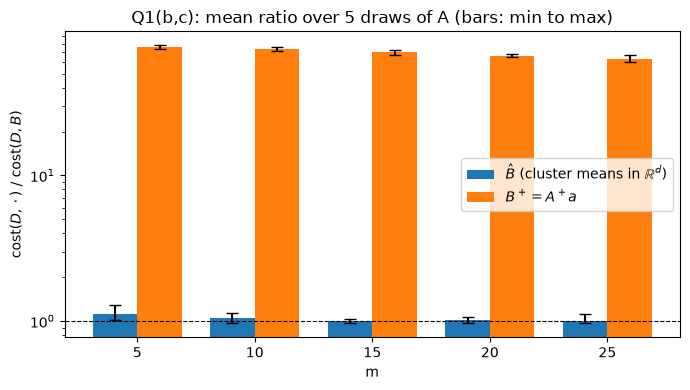

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
g = summ
x = np.arange(len(ms)); w = 0.38
for off, col, lab in [(-w/2, "ratio_Bhat", r"$\hat B$ (cluster means in $\mathbb{R}^d$)"), (w/2, "ratio_Bplus", r"$B^+ = A^+a$")]:
    mean = g[col + "_mean"]; lo = mean - g[col + "_min"]; hi = g[col + "_max"] - mean
    ax.bar(x + off, mean, w, yerr=[lo, hi], capsize=4, label=lab)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(x, ms); ax.set_xlabel("m"); ax.set_ylabel(r"cost$(D,\cdot)$ / cost$(D,B)$")
ax.set_yscale("log"); ax.set_title("Q1(b,c): mean ratio over 5 draws of A (bars: min to max)")
ax.legend(); fig.tight_layout(); fig.savefig("figures/q1_bc_ratios.png", dpi=150); plt.show()

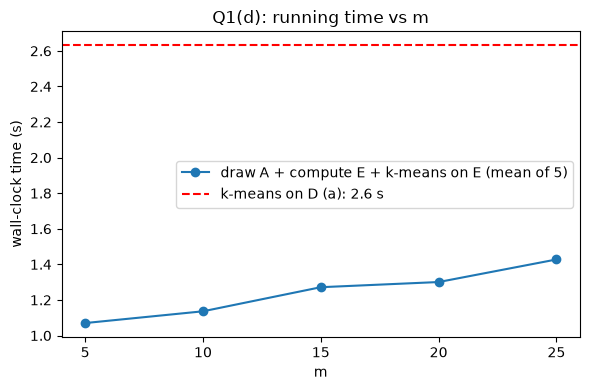

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ms, summ["mean_time_s"], "o-", label="draw A + compute E + k-means on E (mean of 5)")
ax.axhline(time_a, color="r", ls="--", label=f"k-means on D (a): {time_a:.1f} s")
ax.set_xlabel("m"); ax.set_ylabel("wall-clock time (s)"); ax.set_xticks(ms)
ax.set_title("Q1(d): running time vs m"); ax.legend(); fig.tight_layout()
fig.savefig("figures/q1_d_time.png", dpi=150); plt.show()

## (e) Distortion of pairwise distances vs distortion of the k-means cost

In [9]:
rng_e = np.random.default_rng(SEED + 2)
pairs = []
while sum(len(p) for p in pairs) < 10_000:
    i = rng_e.integers(0, n, 20_000); l = rng_e.integers(0, n, 20_000)
    diff = ((D[i].astype(np.float64) - D[l]) ** 2).sum(1)
    keep = (i != l) & (diff > 0)
    pairs.append(np.stack([i[keep], l[keep]], 1))
pairs = np.concatenate(pairs)[:10_000]
I, L = pairs[:, 0], pairs[:, 1]
dD = ((D[I].astype(np.float64) - D[L]) ** 2).sum(1)
costD_CD = partition_cost(D, labels_D, K)
print("pairs:", len(pairs), " min ||D_i-D_l||^2 =", dD.min(), " cost_D(C_D) =", costD_CD)

pair_ratios, cost_ratios = {}, {}
for m in ms:
    A = rng_e.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))       # (i) one draw
    dE = (((D[I].astype(np.float64) - D[L]) @ A.T) ** 2).sum(1)
    pair_ratios[m] = dE / dD
    cr = []
    for _ in range(20):                                       # (ii) 20 draws
        A = rng_e.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
        E = D.astype(np.float64) @ A.T
        cr.append(partition_cost(E, labels_D, K) / costD_CD)
    cost_ratios[m] = np.array(cr)

q1e = pd.DataFrame({m: {"pairs: mean": pair_ratios[m].mean(), "pairs: std": pair_ratios[m].std(),
                        "pairs: 5%": np.percentile(pair_ratios[m], 5), "pairs: 95%": np.percentile(pair_ratios[m], 95),
                        "cost: mean": cost_ratios[m].mean(), "cost: std": cost_ratios[m].std(),
                        "cost: min": cost_ratios[m].min(), "cost: max": cost_ratios[m].max()} for m in ms}).T
q1e.index.name = "m"; q1e.to_csv("results/q1_e_summary.csv"); q1e

pairs: 10000  min ||D_i-D_l||^2 = 5.452588900089642e-13  cost_D(C_D) = 55508.07582236547


,pairs: mean,pairs: std,pairs: 5%,pairs: 95%,cost: mean,cost: std,cost: min,cost: max
m,,,,,,,,
5,0.9368,0.4950,0.3749,1.6028,0.9741,0.0933,0.8061,1.2077
10,1.0247,0.3038,0.6330,1.8842,1.0035,0.1086,0.8634,1.3295
15,0.8139,0.3283,0.3903,1.2608,1.0307,0.0920,0.8508,1.2030
20,0.9000,0.2769,0.5802,1.3140,1.0083,0.0779,0.8904,1.2338
25,1.0872,0.2319,0.7157,1.4761,1.0253,0.0600,0.9082,1.1527


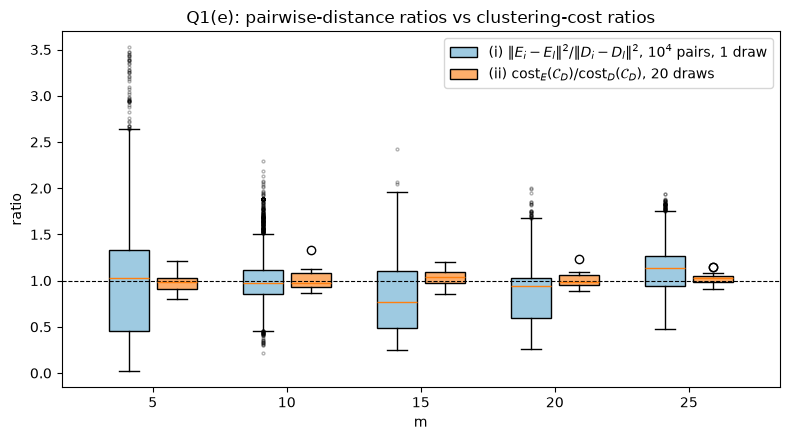

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(ms))
b1 = ax.boxplot([pair_ratios[m] for m in ms], positions=pos - 0.18, widths=0.3, patch_artist=True,
                showfliers=True, flierprops=dict(markersize=2, alpha=0.3))
b2 = ax.boxplot([cost_ratios[m] for m in ms], positions=pos + 0.18, widths=0.3, patch_artist=True)
for p in b1["boxes"]: p.set_facecolor("#9ecae1")
for p in b2["boxes"]: p.set_facecolor("#fdae6b")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(pos, ms); ax.set_xlabel("m"); ax.set_ylabel("ratio")
ax.legend([b1["boxes"][0], b2["boxes"][0]],
          [r"(i) $\|E_i-E_l\|^2/\|D_i-D_l\|^2$, $10^4$ pairs, 1 draw",
           r"(ii) cost$_E(\mathcal{C}_D)$/cost$_D(\mathcal{C}_D)$, 20 draws"])
ax.set_title("Q1(e): pairwise-distance ratios vs clustering-cost ratios")
fig.tight_layout(); fig.savefig("figures/q1_e_boxplots.png", dpi=150); plt.show()

# Question 2: JL for linear regression
## (a) Full least squares

In [11]:
D64 = D.astype(np.float64)
t0 = time.perf_counter()
b = np.linalg.lstsq(D64, y, rcond=None)[0]
time_b = time.perf_counter() - t0
loss_b = float(((D64 @ b - y) ** 2).sum())
print(f"Loss(D, y, b) = {loss_b:.4f}   time to compute b = {time_b:.3f} s   rank(D) = {rankD}")

Loss(D, y, b) = 2949.7888   time to compute b = 1.299 s   rank(D) = 113


## (b), (c) CountSketch

In [12]:
def countsketch(m, Xs, rng):
    """Return S X for each X in Xs without forming S: row i is added with sign sigma(i) to row h(i)."""
    N = Xs[0].shape[0]
    h = rng.integers(0, m, size=N)
    sigma = rng.choice(np.array([-1.0, 1.0]), size=N)
    out = []
    for X in Xs:
        Xv = X if X.ndim == 2 else X[:, None]
        SX = np.zeros((m, Xv.shape[1]))
        np.add.at(SX, h, sigma[:, None] * Xv)
        out.append(SX if X.ndim == 2 else SX[:, 0])
    return out

ms2 = [50, 100, 200, 500, 1000, 2000, 5000]
rng2 = np.random.default_rng(SEED + 3)
rows = []
for m in ms2:
    for r in range(5):
        t0 = time.perf_counter()
        SD, Sy = countsketch(m, [D64, y], rng2)
        a_t = np.linalg.lstsq(SD, Sy, rcond=None)[0]
        t = time.perf_counter() - t0
        loss = float(((D64 @ a_t - y) ** 2).sum())
        rows.append(dict(m=m, run=r + 1, loss=loss, ratio=loss / loss_b,
                         sketched_loss=float(((SD @ a_t - Sy) ** 2).sum()), time_s=t))
q2 = pd.DataFrame(rows); q2.to_csv("results/q2_runs.csv", index=False)
q2s = q2.groupby("m").agg(loss_mean=("loss", "mean"), ratio_mean=("ratio", "mean"), ratio_min=("ratio", "min"),
                          ratio_max=("ratio", "max"), sketched_loss_mean=("sketched_loss", "mean"),
                          time_mean_s=("time_s", "mean"))
q2s["time_vs_full"] = q2s["time_mean_s"] / time_b
q2s.to_csv("results/q2_summary.csv")
print(f"Loss(D,y,b) = {loss_b:.4f}, time for b = {time_b:.3f} s")
q2s

Loss(D,y,b) = 2949.7888, time for b = 1.299 s


,loss_mean,ratio_mean,ratio_min,ratio_max,sketched_loss_mean,time_mean_s,time_vs_full
m,,,,,,,
50,10191.3684,3.4549,3.0259,4.5081,8.8454e-24,0.3141,0.2419
100,48574.7396,16.4672,10.9055,24.9279,2.4537e-23,0.3270,0.2518
200,6266.9542,2.1245,1.9806,2.2458,1.4069e+03,0.3134,0.2413
500,3830.1082,1.2984,1.2441,1.3598,2.2961e+03,0.3137,0.2416
1000,3315.2979,1.1239,1.1030,1.1619,2.5334e+03,0.3155,0.2430
2000,3131.5159,1.0616,1.0508,1.0675,2.8476e+03,0.3179,0.2448
5000,3021.7148,1.0244,1.0196,1.0292,2.8874e+03,0.3223,0.2482


In [13]:
q2

,m,run,loss,ratio,sketched_loss,time_s
0,50,1,13297.8168,4.5081,9.6775e-25,0.3334
1,50,2,9809.2638,3.3254,1.5404e-23,0.3087
2,50,3,8925.7782,3.0259,1.8385e-23,0.3091
3,50,4,9244.5514,3.1340,7.7750e-24,0.3101
4,50,5,9679.4320,3.2814,1.6953e-24,0.3091
5,100,1,73532.0799,24.9279,4.0756e-23,0.3513
6,100,2,42907.7094,14.5460,4.1182e-23,0.3151
7,100,3,32168.9487,10.9055,1.8876e-23,0.3125
8,100,4,42264.3349,14.3279,5.7363e-24,0.3120
9,100,5,52000.6249,17.6286,1.6132e-23,0.3443


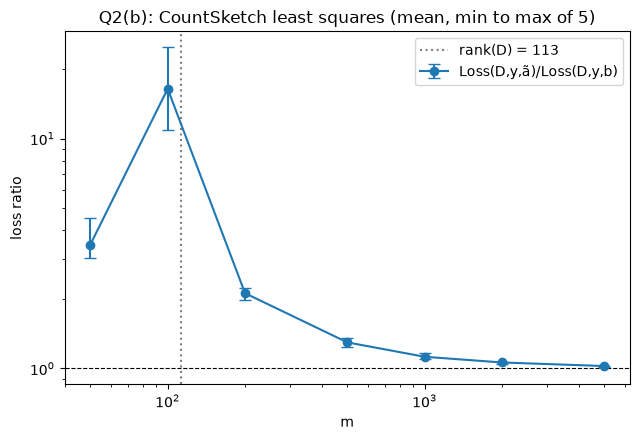

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
mm = q2s.index.values
ax.errorbar(mm, q2s.ratio_mean, yerr=[q2s.ratio_mean - q2s.ratio_min, q2s.ratio_max - q2s.ratio_mean],
            fmt="o-", capsize=4, label="Loss(D,y,ã)/Loss(D,y,b)")
ax.axvline(rankD, color="gray", ls=":", label=f"rank(D) = {rankD}")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("m"); ax.set_ylabel("loss ratio")
ax.set_title("Q2(b): CountSketch least squares (mean, min to max of 5)"); ax.legend()
fig.tight_layout(); fig.savefig("figures/q2_b_ratio.png", dpi=150); plt.show()

## (d) Norm preservation of the residual

In [15]:
v = D64 @ b - y
vn = (v ** 2).sum()
rng_d = np.random.default_rng(SEED + 4)
norm_ratios = {}
for m in [50, 500, 5000]:
    norm_ratios[m] = np.array([(countsketch(m, [v], rng_d)[0] ** 2).sum() / vn for _ in range(100)])
q2d = pd.DataFrame({m: {"mean": r.mean(), "std": r.std(ddof=1), "min": r.min(), "max": r.max(),
                        "theory std sqrt(2/m)": np.sqrt(2 / m)} for m, r in norm_ratios.items()}).T
q2d.index.name = "m"; q2d.to_csv("results/q2_d_summary.csv"); q2d

,mean,std,min,max,theory std sqrt(2/m)
m,,,,,
50,0.9926,0.1862,0.6207,1.5965,0.2000
500,1.0038,0.0616,0.8749,1.1982,0.0632
5000,1.0013,0.0201,0.9554,1.0387,0.0200


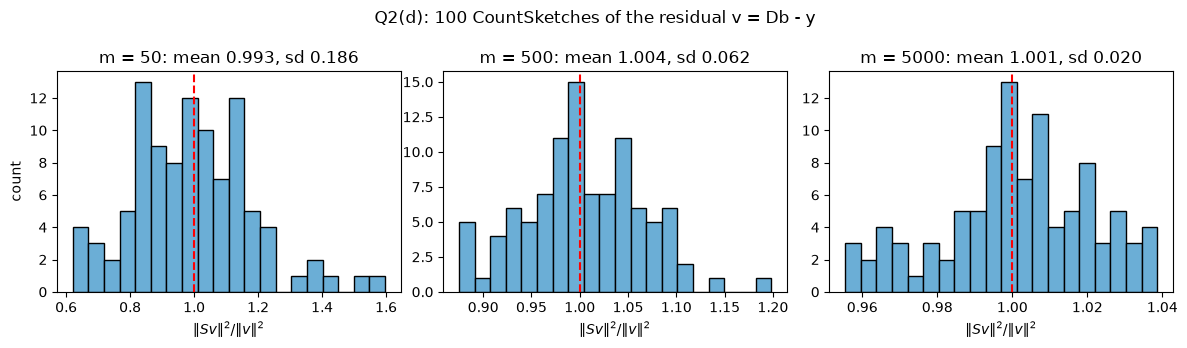

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (m, r) in zip(axs, norm_ratios.items()):
    ax.hist(r, bins=20, color="#6baed6", edgecolor="k")
    ax.axvline(1, color="r", ls="--")
    ax.set_title(f"m = {m}: mean {r.mean():.3f}, sd {r.std(ddof=1):.3f}")
    ax.set_xlabel(r"$\|Sv\|^2/\|v\|^2$")
axs[0].set_ylabel("count")
fig.suptitle("Q2(d): 100 CountSketches of the residual v = Db - y"); fig.tight_layout()
fig.savefig("figures/q2_d_hist.png", dpi=150); plt.show()

## (e) CountSketch vs dense Gaussian sketch on a 50,000-row subset

In [17]:
rng_sub = np.random.default_rng(SEED + 5)
idx = rng_sub.choice(n, size=50_000, replace=False)
Dp, yp = D64[idx], y[idx]
bp = np.linalg.lstsq(Dp, yp, rcond=None)[0]
loss_bp = float(((Dp @ bp - yp) ** 2).sum())
print(f"Loss(D', y', b') = {loss_bp:.4f}")

m = 500
rng_e2 = np.random.default_rng(SEED + 6)
rows = []
for r in range(5):
    # (i) CountSketch
    t0 = time.perf_counter()
    SD, Sy = countsketch(m, [Dp, yp], rng_e2)
    t_cs = time.perf_counter() - t0
    a_cs = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    # (ii) dense Gaussian
    t0 = time.perf_counter()
    S = rng_e2.normal(0.0, 1.0 / np.sqrt(m), size=(m, Dp.shape[0]))
    SD, Sy = S @ Dp, S @ yp
    t_g = time.perf_counter() - t0
    a_g = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    for name, a, t in [("CountSketch", a_cs, t_cs), ("Gaussian", a_g, t_g)]:
        rows.append(dict(sketch=name, run=r + 1, time_s=t,
                         ratio=float(((Dp @ a - yp) ** 2).sum()) / loss_bp))
q2e = pd.DataFrame(rows); q2e.to_csv("results/q2_e_runs.csv", index=False)
q2e_s = q2e.groupby("sketch").agg(time_mean_s=("time_s", "mean"), ratio_mean=("ratio", "mean"),
                                  ratio_min=("ratio", "min"), ratio_max=("ratio", "max"))
q2e_s.to_csv("results/q2_e_summary.csv"); q2e_s

Loss(D', y', b') = 203.1570


,time_mean_s,ratio_mean,ratio_min,ratio_max
sketch,,,,
CountSketch,0.0298,1.2948,1.2667,1.3135
Gaussian,0.1124,1.2867,1.2482,1.3353
